# Rainfall Prediction System

## 1) System / Business Description
The system on which I will be working is Rainfall Prediction. The System is a data-driven solution designed to forecast rainfall in specific regions using Machine Learning techniques. Accurate rainfall predictions are critical for agriculture, water resource management, and disaster preparedness. The system uses historical weather data and other environmental factors to predict future rainfall levels, enabling informed decision-making for stakeholders such as farmers, and agriculture agencies. This system will collect weather-related data such as temperature, humidity, wind speed, and past rainfall patterns and then I will apply Machine Learning models to analyze patterns and relationships within the data. This would also benefit farmers since they will be able to organize their planting and harvesting seasons more effectively. 

## 2) Problem or issues being addressed
Accurate rainfall prediction is a complex problem due to the dynamic and interdependent nature of meteorological factors. Traditional statistical methods often fail to capture these complexities, leading to unreliable forecasts. This unpredictability can result in poor planning, agricultural losses, and inadequate disaster management such as floods and similar extreme events are consequences of climate change that are expected to occur
more frequently and have catastrophic effects in years to come. By using Machine Learning, this system aims to improve prediction accuracy, enabling better preparedness and resource allocation.

## 3) Solutions (How ML can help)
Machine Learning algorithms can analyze vast amounts of historical weather data and identify non-linear relationships between various factors affecting rainfall, such as temperature, pressure, and wind patterns. By training models like Linear Regression, Decision Trees, or Neural Networks, the system can make precise and timely predictions. These predictions allow for data-driven decision-making, reducing uncertainty and improving planning in agriculture, water management, and disaster mitigation.

## 4) Dataset Description
The dataset required for this project consists of weather and climate-related data collected over several years. I have explored 'kaggle' 'hugging face'
'data.gov' and have received multiple datasets regarding my topic. Meteorological data will include temperature (minimum, maximum, and average in °C), humidity levels (%), atmospheric pressure (hPa), wind speed (km/h or m/s), and wind direction. Our target variable will be rainfall (in mm).
The particular dataset that I will be collecting focuses on meteorological parameters like temperature, humidity, pressure, and other relevant features.
It provides clean, tabular data with labeled rainfall values, suitable for regression models. The dataset structure is simple and can easily be loaded.

In [74]:
## 5) Dataset Collection
!pip install pandas
import pandas as pd
print(pd.__version__)
import pandas as pd
df = pd.read_csv('Rainfall.csv') 
df

2.2.3


,day,pressure,maxtemp,temparature,mintemp,dewpoint,humidity,cloud,rainfall,sunshine,winddirection,windspeed
0,1,1025.9,19.9,18.3,16.8,13.1,72,49,yes,9.3,80.0,26.3
1,2,1022.0,21.7,18.9,17.2,15.6,81,83,yes,0.6,50.0,15.3
2,3,1019.7,20.3,19.3,18.0,18.4,95,91,yes,0.0,40.0,14.2
3,4,1018.9,22.3,20.6,19.1,18.8,90,88,yes,1.0,50.0,16.9
4,5,1015.9,21.3,20.7,20.2,19.9,95,81,yes,0.0,40.0,13.7
...,...,...,...,...,...,...,...,...,...,...,...,...
361,27,1022.7,18.8,17.7,16.9,15.0,84,90,yes,0.0,30.0,18.4
362,28,1026.6,18.6,17.3,16.3,12.8,75,85,yes,1.0,20.0,25.9
363,29,1025.9,18.9,17.7,16.4,13.3,75,78,yes,4.6,70.0,33.4
364,30,1025.3,19.2,17.3,15.2,13.3,78,86,yes,1.2,20.0,20.9


## 6) preprocessing 
Steps for preprocessing data:
1) Import necessary libraries
2) Read Dataset
3) Sanity check of data
4) EDA - Exploratory Data Analysis
5) Missing values treatment
6) duplicate and garbage value treatment
7) Outlier treatments
8) Normalization
9) Encoding of data

In [70]:
#Step 1
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [71]:
#Step 2 
df = pd.read_csv('Rainfall.csv')
df.head()
df.tail()

,day,pressure,maxtemp,temparature,mintemp,dewpoint,humidity,cloud,rainfall,sunshine,winddirection,windspeed
361,27,1022.7,18.8,17.7,16.9,15.0,84,90,yes,0.0,30.0,18.4
362,28,1026.6,18.6,17.3,16.3,12.8,75,85,yes,1.0,20.0,25.9
363,29,1025.9,18.9,17.7,16.4,13.3,75,78,yes,4.6,70.0,33.4
364,30,1025.3,19.2,17.3,15.2,13.3,78,86,yes,1.2,20.0,20.9
365,31,1026.4,20.5,17.8,15.5,13.0,74,66,no,5.7,20.0,23.3


In [46]:
#Step 3 (checking if all ok?)
df.shape
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 366 entries, 0 to 365
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   day                     366 non-null    int64  
 1   pressure                366 non-null    float64
 2   maxtemp                 366 non-null    float64
 3   temparature             366 non-null    float64
 4   mintemp                 366 non-null    float64
 5   dewpoint                366 non-null    float64
 6   humidity                366 non-null    int64  
 7   cloud                   366 non-null    int64  
 8   rainfall                366 non-null    object 
 9   sunshine                366 non-null    float64
 10           winddirection  365 non-null    float64
 11  windspeed               365 non-null    float64
dtypes: float64(8), int64(3), object(1)
memory usage: 34.4+ KB


In [43]:
#finding missing value (no missing value in dataset)
df.isnull().sum()

day                       0
pressure                  0
maxtemp                   0
temparature               0
mintemp                   0
dewpoint                  0
humidity                  0
cloud                     0
rainfall                  0
sunshine                  0
         winddirection    1
windspeed                 1
dtype: int64

In [50]:
#finding duplicate
df.duplicated().sum()

np.int64(0)

In [63]:
# identify garbage value
print("Identifying garbage values...\n")
for col in df.select_dtypes(include="object").columns:
    print(f"Column: {col}")
    print(df[col].value_counts())  
    print("-" * 30)

Identifying garbage values...

Column: rainfall
rainfall
yes    249
no     117
Name: count, dtype: int64
------------------------------


In [65]:
# Step4: EDA
df.describe()

,day,pressure,maxtemp,temparature,mintemp,dewpoint,humidity,cloud,sunshine,winddirection,windspeed
count,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,365.000000,365.000000
mean,15.756831,1013.742623,26.191257,23.747268,21.894536,19.989071,80.177596,71.128415,4.419399,101.506849,21.536986
std,8.823592,6.414776,5.978343,5.632813,5.594153,5.997021,10.062470,21.798012,3.934398,81.723724,10.069712
min,1.000000,998.500000,7.100000,4.900000,3.100000,-0.400000,36.000000,0.000000,0.000000,10.000000,4.400000
25%,8.000000,1008.500000,21.200000,18.825000,17.125000,16.125000,75.000000,58.000000,0.500000,40.000000,13.700000
50%,16.000000,1013.000000,27.750000,25.450000,23.700000,21.950000,80.500000,80.000000,3.500000,70.000000,20.500000
75%,23.000000,1018.100000,31.200000,28.600000,26.575000,25.000000,87.000000,88.000000,8.200000,190.000000,27.900000
max,31.000000,1034.600000,36.300000,32.400000,30.000000,26.700000,98.000000,100.000000,12.100000,350.000000,59.500000


In [66]:
df.describe(include="object")

,rainfall
count,366
unique,2
top,yes
freq,249


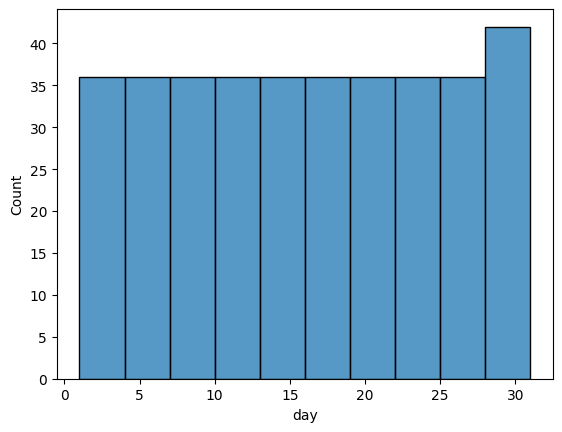

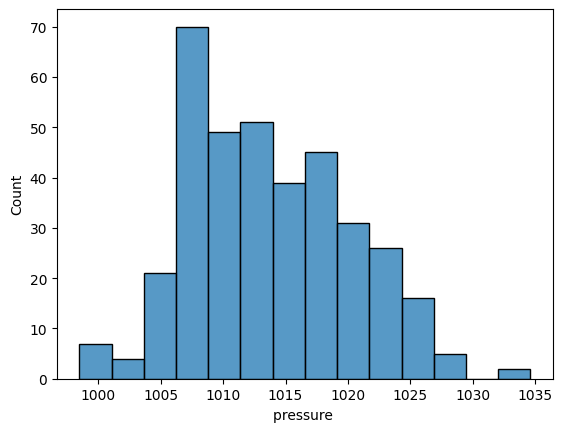

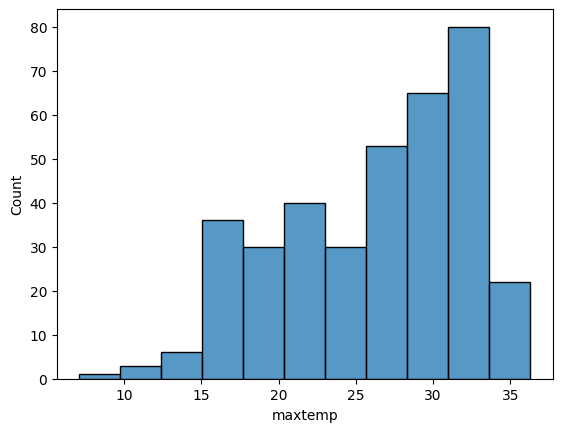

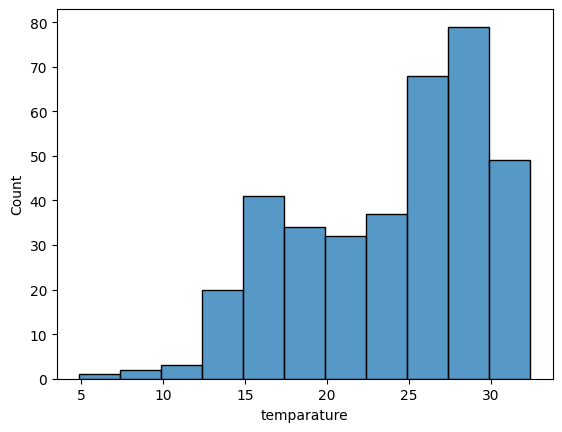

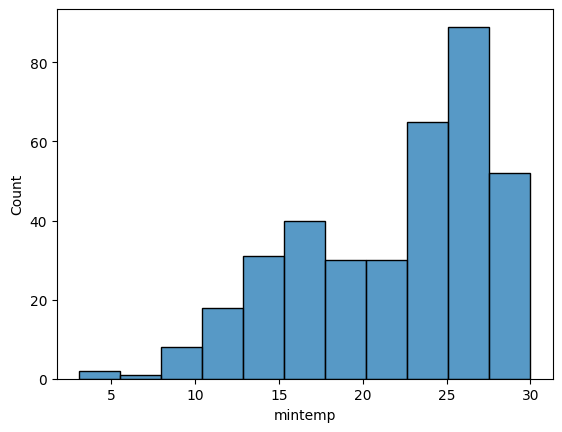

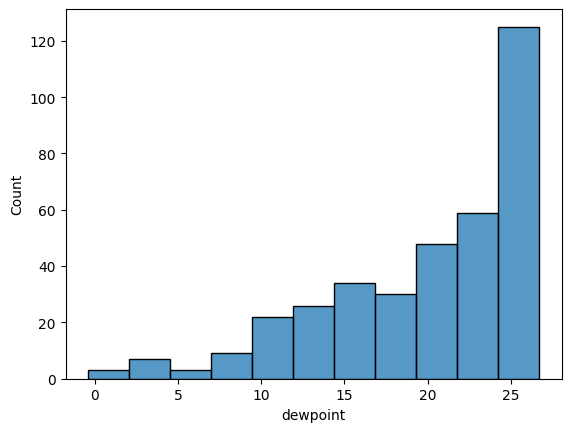

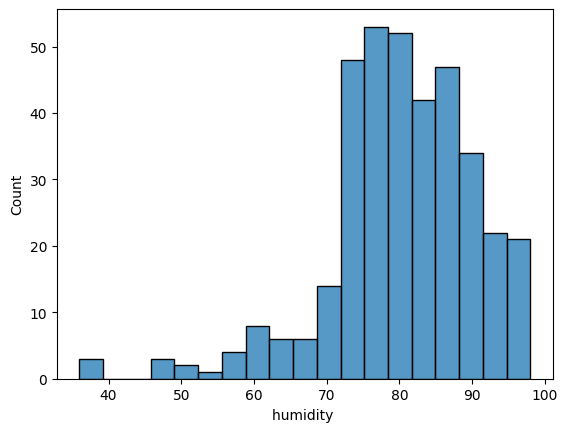

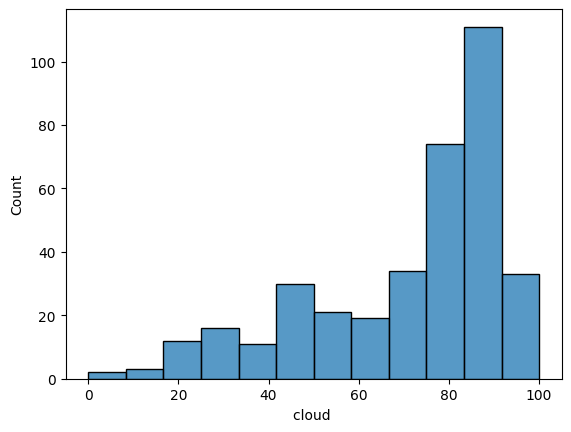

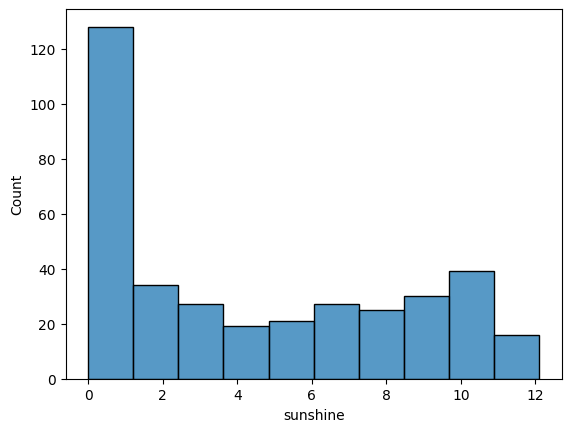

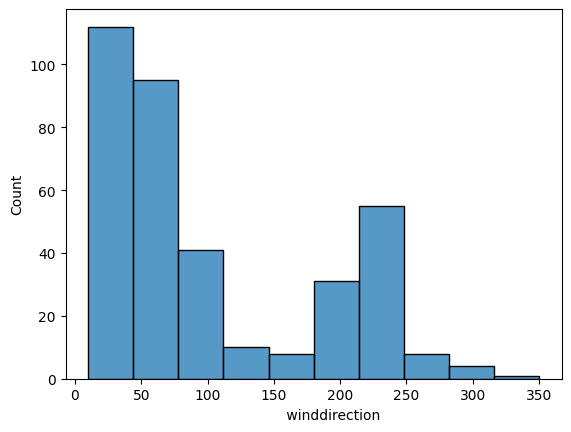

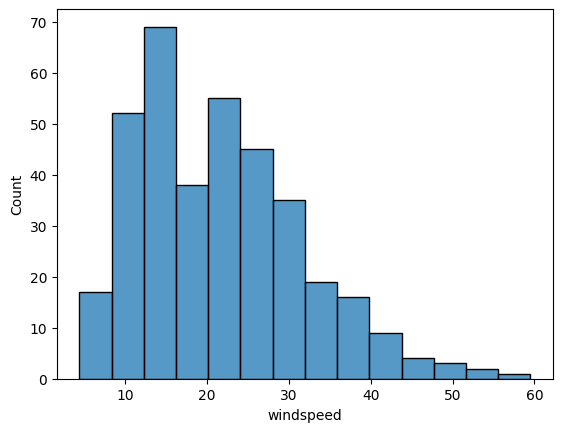

In [73]:
for i in df.select_dtypes(include="number").columns:
    sns.histplot(data=df, x=i) 
    plt.show()

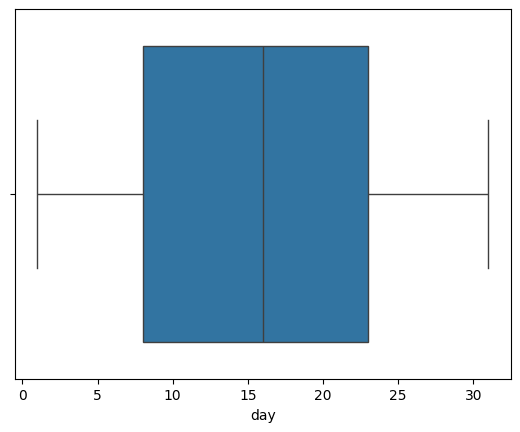

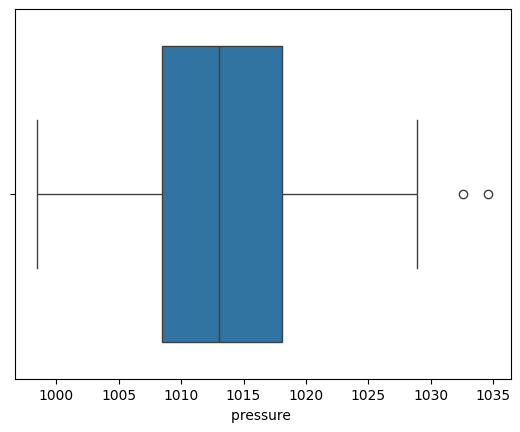

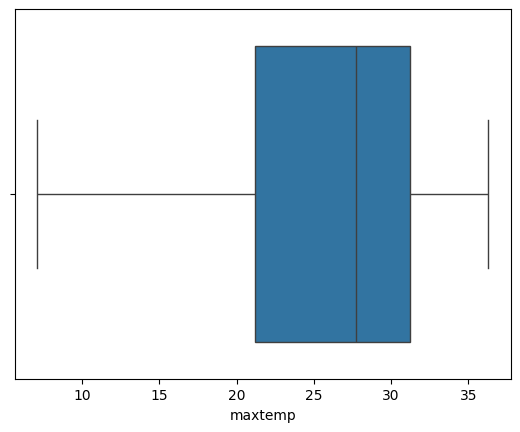

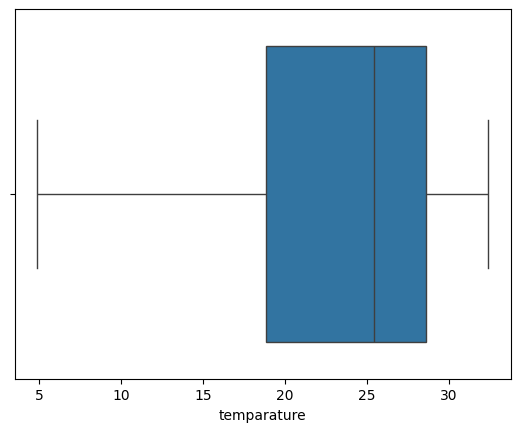

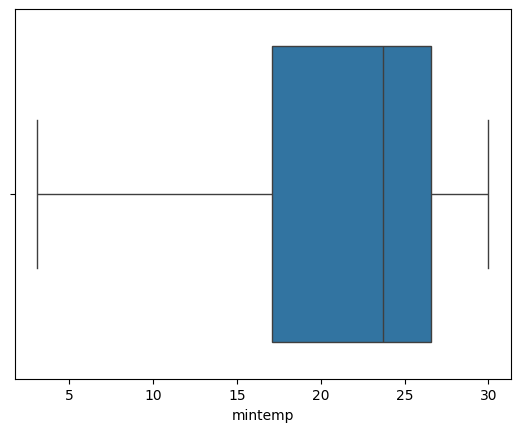

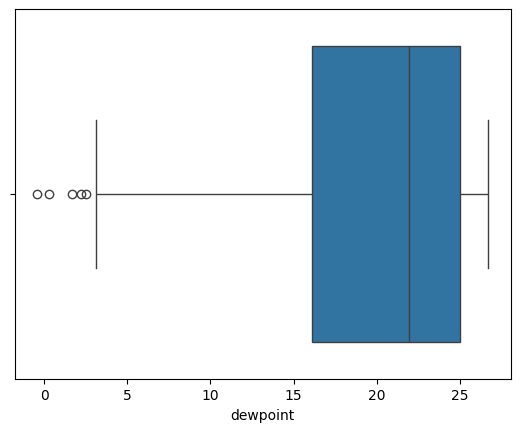

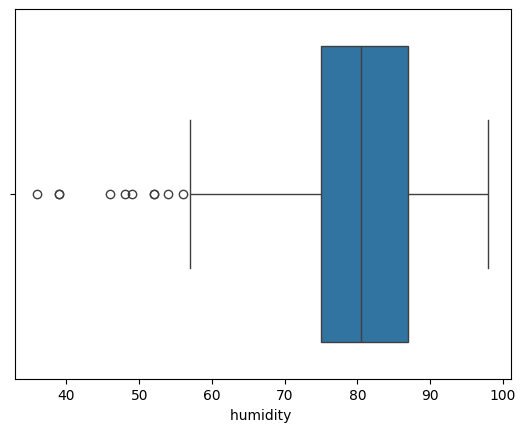

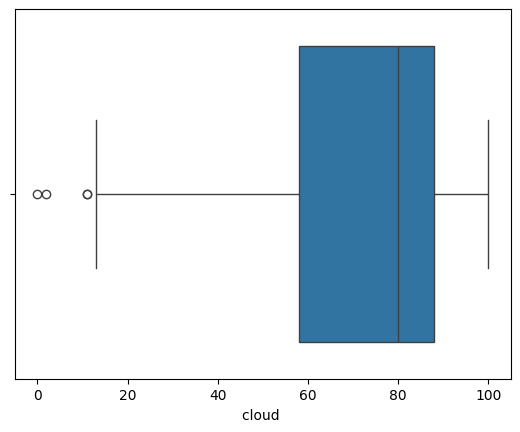

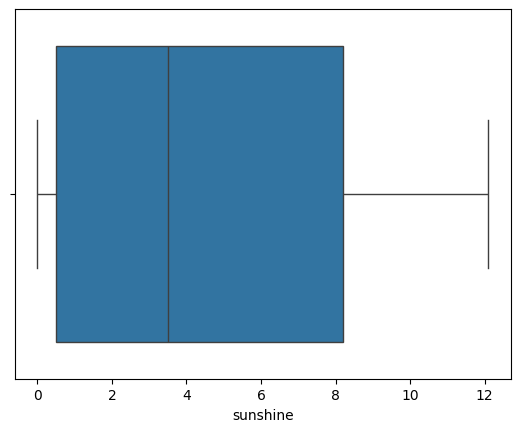

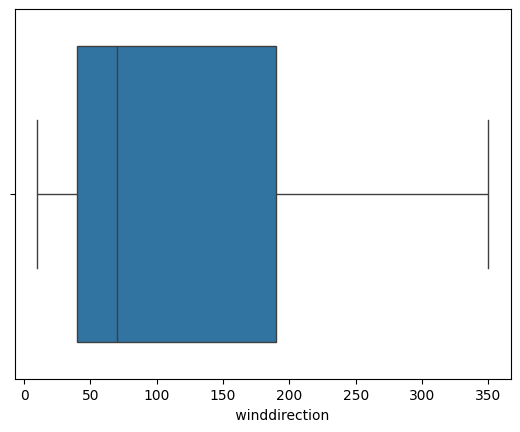

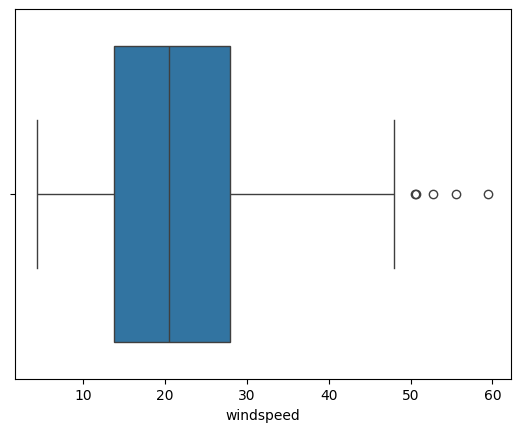

In [75]:
for i in df.select_dtypes(include="number").columns:
    sns.boxplot(data=df, x=i) 
    plt.show()

Column 'pressure' not found in DataFrame


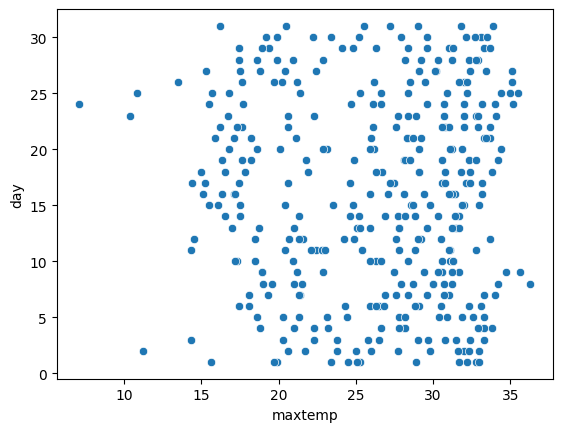

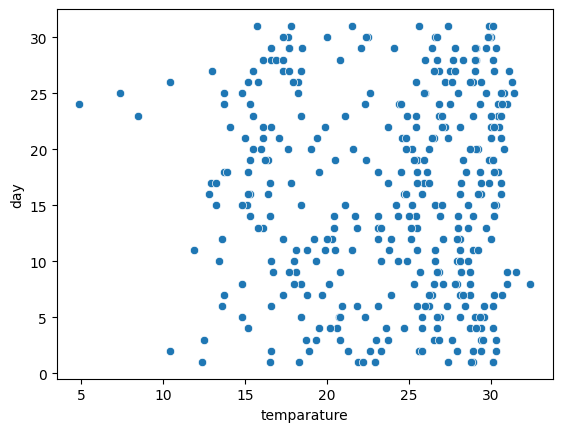

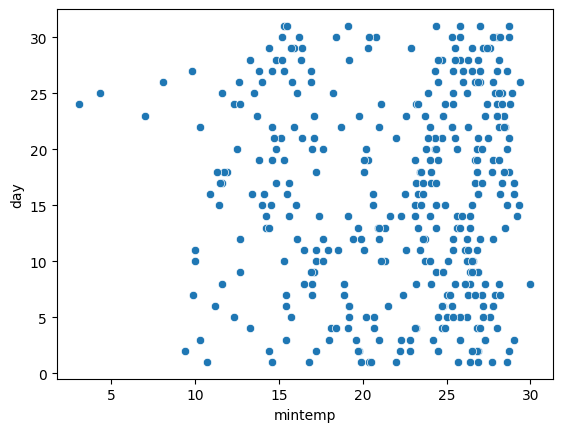

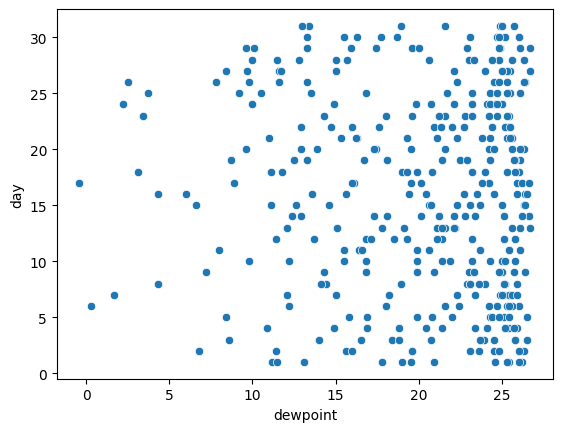

Column 'humidity' not found in DataFrame
Column 'cloud' not found in DataFrame


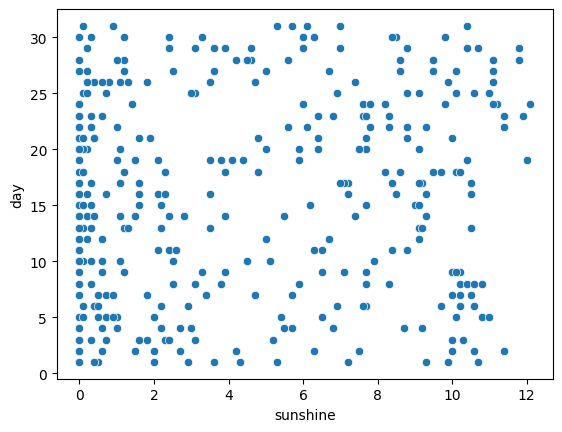

Column 'wind direction' not found in DataFrame


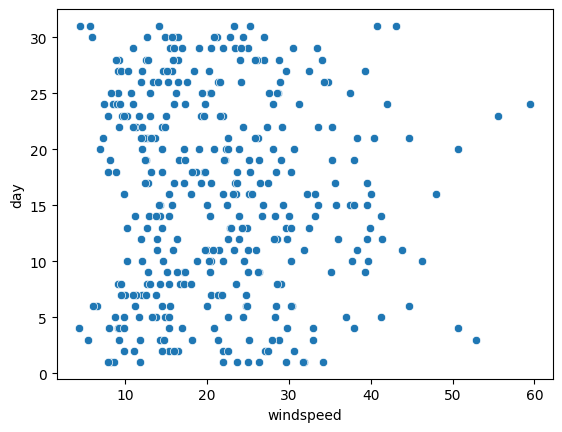

In [84]:
for i in ['pressure', 'maxtemp', 'temparature', 'mintemp', 'dewpoint',
          'humidity', 'cloud', 'sunshine', 'wind direction', 'windspeed']:
    if i not in df.columns:
        print(f"Column '{i}' not found in DataFrame")
    elif not (df[i].dtype == 'int64' or df[i].dtype == 'float64'):
        print(f"Column '{i}' is not numeric")
    else:
        sns.scatterplot(data=df, x=i, y='day')
        plt.show()


In [16]:
#step 5
import pandas as pd
df = pd.read_csv('Rainfall.csv') 
print(df.isnull().sum())
print(df.isnull().sum() / len(df) * 100)

day                       0
pressure                  0
maxtemp                   0
temparature               0
mintemp                   0
dewpoint                  0
humidity                  0
cloud                     0
rainfall                  0
sunshine                  0
         winddirection    1
windspeed                 1
dtype: int64
day                       0.000000
pressure                  0.000000
maxtemp                   0.000000
temparature               0.000000
mintemp                   0.000000
dewpoint                  0.000000
humidity                  0.000000
cloud                     0.000000
rainfall                  0.000000
sunshine                  0.000000
         winddirection    0.273224
windspeed                 0.273224
dtype: float64


In [23]:
# Step 7
def wisker(col):
    q1, q3 = np.percentile(col, [25, 75])
    iiqr = q3 - q1
    lw = q1 - 1.5 * iiqr
    uw = q3 + 1.5 * iiqr
    return lw, uw

In [26]:
df.columns = df.columns.str.strip()

In [34]:
print(df['rainfall'].dtype)  
print(df['rainfall'].isnull().sum())  
print(df['rainfall'].unique()) 

object
0
['yes' 'no']


In [35]:
df['rainfall'] = pd.to_numeric(df['rainfall'], errors='coerce')  

In [ ]:
df['rainfall'].fillna(df['rainfall'].mean(), inplace=True)

In [38]:
# Normalize the 'rainfall' column manually
df['rainfall_normalized'] = (df['rainfall'] - df['rainfall'].min()) / (df['rainfall'].max() - df['rainfall'].min())

print(df[['rainfall', 'rainfall_normalized']])

     rainfall  rainfall_normalized
0         NaN                  NaN
1         NaN                  NaN
2         NaN                  NaN
3         NaN                  NaN
4         NaN                  NaN
..        ...                  ...
361       NaN                  NaN
362       NaN                  NaN
363       NaN                  NaN
364       NaN                  NaN
365       NaN                  NaN

[366 rows x 2 columns]


In [41]:
pd.get_dummies(data=df, columns=["temparature"], drop_first=True)

,day,pressure,maxtemp,mintemp,dewpoint,humidity,cloud,rainfall,sunshine,winddirection,...,temparature_30.5,temparature_30.6,temparature_30.7,temparature_30.8,temparature_31.0,temparature_31.1,temparature_31.3,temparature_31.4,temparature_31.5,temparature_32.4
0,1,1025.9,19.9,16.8,13.1,72,49,NaN,9.3,80.0,...,False,False,False,False,False,False,False,False,False,False
1,2,1022.0,21.7,17.2,15.6,81,83,NaN,0.6,50.0,...,False,False,False,False,False,False,False,False,False,False
2,3,1019.7,20.3,18.0,18.4,95,91,NaN,0.0,40.0,...,False,False,False,False,False,False,False,False,False,False
3,4,1018.9,22.3,19.1,18.8,90,88,NaN,1.0,50.0,...,False,False,False,False,False,False,False,False,False,False
4,5,1015.9,21.3,20.2,19.9,95,81,NaN,0.0,40.0,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
361,27,1022.7,18.8,16.9,15.0,84,90,NaN,0.0,30.0,...,False,False,False,False,False,False,False,False,False,False
362,28,1026.6,18.6,16.3,12.8,75,85,NaN,1.0,20.0,...,False,False,False,False,False,False,False,False,False,False
363,29,1025.9,18.9,16.4,13.3,75,78,NaN,4.6,70.0,...,False,False,False,False,False,False,False,False,False,False
364,30,1025.3,19.2,15.2,13.3,78,86,NaN,1.2,20.0,...,False,False,False,False,False,False,False,False,False,False


In [42]:
df.columns = df.columns.str.strip()

In [43]:
pd.get_dummies(data=df, columns=["pressure"], drop_first=True)

,day,maxtemp,temparature,mintemp,dewpoint,humidity,cloud,rainfall,sunshine,winddirection,...,pressure_1025.9,pressure_1026.1,pressure_1026.4,pressure_1026.6,pressure_1027.1,pressure_1027.4,pressure_1027.5,pressure_1028.9,pressure_1032.6,pressure_1034.6
0,1,19.9,18.3,16.8,13.1,72,49,NaN,9.3,80.0,...,True,False,False,False,False,False,False,False,False,False
1,2,21.7,18.9,17.2,15.6,81,83,NaN,0.6,50.0,...,False,False,False,False,False,False,False,False,False,False
2,3,20.3,19.3,18.0,18.4,95,91,NaN,0.0,40.0,...,False,False,False,False,False,False,False,False,False,False
3,4,22.3,20.6,19.1,18.8,90,88,NaN,1.0,50.0,...,False,False,False,False,False,False,False,False,False,False
4,5,21.3,20.7,20.2,19.9,95,81,NaN,0.0,40.0,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
361,27,18.8,17.7,16.9,15.0,84,90,NaN,0.0,30.0,...,False,False,False,False,False,False,False,False,False,False
362,28,18.6,17.3,16.3,12.8,75,85,NaN,1.0,20.0,...,False,False,False,True,False,False,False,False,False,False
363,29,18.9,17.7,16.4,13.3,75,78,NaN,4.6,70.0,...,True,False,False,False,False,False,False,False,False,False
364,30,19.2,17.3,15.2,13.3,78,86,NaN,1.2,20.0,...,False,False,False,False,False,False,False,False,False,False


In [45]:
from sklearn.model_selection import train_test_split
df.columns = df.columns.str.strip()

X = df.drop(columns=['rainfall']) 
y = df['rainfall'].map({'yes': 1, 'no': 0}) 

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Check the Shape of the Data Splits
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features Shape: (292, 12)
Testing Features Shape: (74, 12)
Training Target Shape: (292,)
Testing Target Shape: (74,)
